In [1]:
from IPython.display import Image, display

from src.collection import Collection
from src.tag.yolo import YOLOTagger

&nbsp;

### **📂 Open collection**

In [2]:
collection = Collection()

Open Collection: E:\Resources\Eyeris\Test


&nbsp;

### **🖼️ Load all images**

In [3]:
images = collection.images_df()
images.head()

,id,origin,fullname,name,format,size,width,height,created,modified,rating,tags,hash,color_1,color_2,color_3,color_4,path,thumb_path
0,1,E:/Resources/Dataset/012.webp,012.webp,012,WEBP,8432346,3840,2160,1794203991530,1769960112000,4,lakeside,c34db2d144df3ff432eb28ce6efeaa0cc54c29aa2d7085...,7310413,3890462,9347248.0,1052676.0,E:\Resources\Eyeris\Test/images/c34db2d144df3f...,E:\Resources\Eyeris\Test/images/c34db2d144df3f...
1,2,E:/Resources/Dataset/voxel-houses-monochrome.webp,voxel-houses-monochrome.webp,voxel-houses-monochrome,WEBP,1796402,3840,2160,1794203991530,1789570720000,4,tank,9e032b32ece9a229983de22905af98e6de70b6e4597cd2...,4474458,1710888,2829372.0,6645627.0,E:\Resources\Eyeris\Test/images/9e032b32ece9a2...,E:\Resources\Eyeris\Test/images/9e032b32ece9a2...
2,3,E:/Resources/Dataset/house_garden.webp,house_garden.webp,house_garden,WEBP,483728,3840,2160,1794203991530,1789570720000,4,restaurant,e6cf0e8ff0304d0217fb1c591c98aaf75bb526532c135a...,13745760,11562290,5723436.0,2962979.0,E:\Resources\Eyeris\Test/images/e6cf0e8ff0304d...,E:\Resources\Eyeris\Test/images/e6cf0e8ff0304d...
3,4,E:/Resources/Dataset/macos-sonoma-wallpapers-5...,macos-sonoma-wallpapers-5120x2160-v0-q59obfq8h...,macos-sonoma-wallpapers-5120x2160-v0-q59obfq8h...,WEBP,5075530,5120,2160,1794203991530,1789570720000,5,cliff,bc1cc32311ef499f47ea59370365d1a3d9cc1546d2b261...,8029334,12697530,2499359.0,5065546.0,E:\Resources\Eyeris\Test/images/bc1cc32311ef49...,E:\Resources\Eyeris\Test/images/bc1cc32311ef49...
4,5,E:/Resources/Dataset/dream-river-4k.webp,dream-river-4k.webp,dream-river-4k,WEBP,7172958,3840,2160,1794203991530,1789570720000,5,lakeside,37033841e3ba46af1a3cf31f8e948d5850bccca469c1e3...,11037095,6238318,15121103.0,2887729.0,E:\Resources\Eyeris\Test/images/37033841e3ba46...,E:\Resources\Eyeris\Test/images/37033841e3ba46...


&nbsp;

### **🏷️ Tag it!**

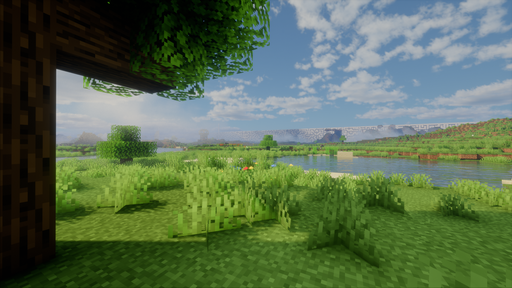

Tags: ['lakeside']


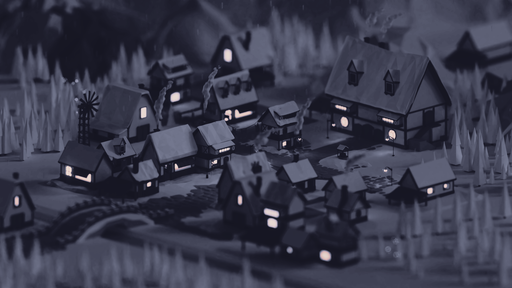

Tags: ['tank']


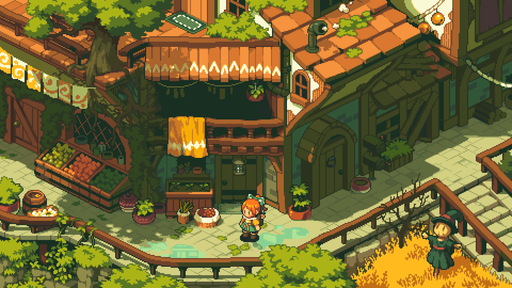

Tags: ['restaurant']


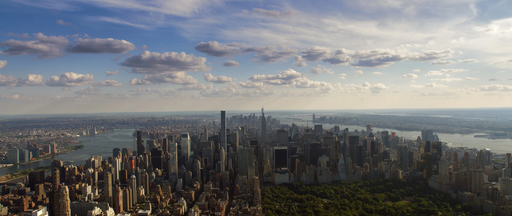

Tags: ['cliff']


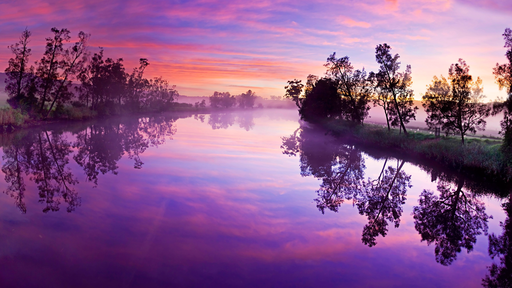

Tags: ['lakeside']


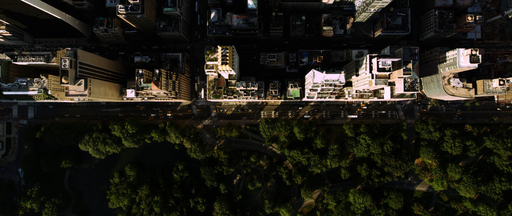

Tags: []


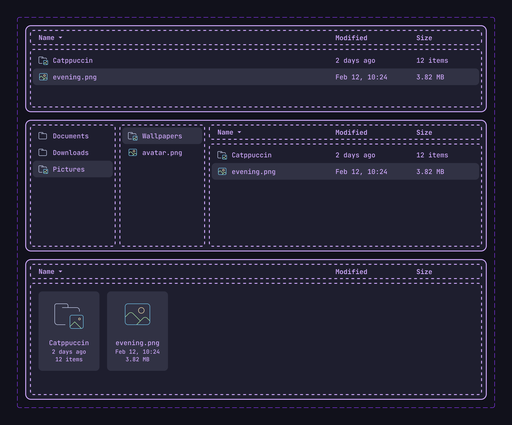

Tags: ['web_site']


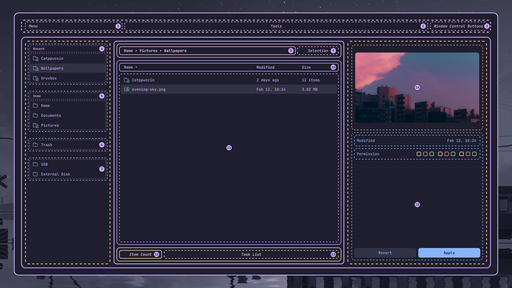

Tags: []


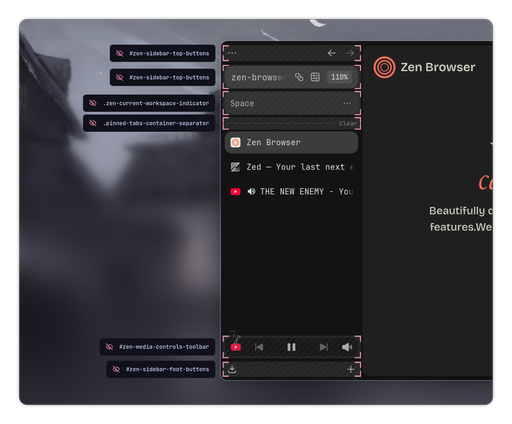

Tags: ['web_site']


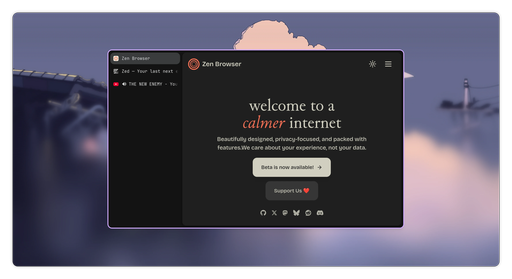

Tags: ['web_site']


In [4]:
tagger = YOLOTagger()
logs = []

for i, image in enumerate(images[::].itertuples()):
    tags = tagger.tag(image.path)
    if tags:
        merged_tags = "|".join(list(set(image.tags.split("|") + tags))).strip("|")
        logs.append({"id": image.id, "tags": merged_tags})
    if i < 10:
        display(Image(filename=image.thumb_path, width=96))
        print(f"Tags: {tags}")

&nbsp;

### ✍️ **Write back to database**

In [ ]:
for log in logs:
    collection.db.execute("UPDATE images SET tags = ? WHERE id = ?", (log["tags"], log["id"]))
collection.db.commit()